# 32 - Held-out intervention test: multi-token prediction (MTP)

The protocol's rules so far (3-4 rungs past the turn + linear for short range; polynomials break at
half a decade; effects saturate) were derived from the two interventions used to build it. This
notebook tests the protocol on an intervention it has never seen: **MTP** (auxiliary t+2 prediction
head, weight 0.5, training only - eval ppl stays pure next-token CE). Known from the literature to
hurt small models and help large ones (Gloeckle et al. 2024, at >=3B) - what it does at 5M-91M under
a fixed small budget is unknown. Combo baselines at every size already exist, so we only train the
MTP arm.

Order of cells enforces honesty: ladder -> fit + **pre-register 91M forecast** -> only then 91M runs.
New fit family introduced here: **bounded saturating form** Delta(x) = a + b*exp(-k*(x-x0)),
motivated by the observed saturation; its credibility is first checked by retrodicting the known
conv/diff 91M outcomes from <=29.4M data.


In [1]:
%matplotlib inline
import os, math, time, csv, json, gc
from contextlib import nullcontext
import numpy as np
import torch
from model import Config, GPT, count_params

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
D = "../dataset"
train_data = torch.from_numpy(np.load(D + "/wt103_bpe_train.npy"))
val_data = torch.from_numpy(np.load(D + "/wt103_bpe_val.npy"))
vocab = json.load(open(D + "/wt103_bpe_meta.json"))["vocab"]
print(f"vocab={vocab}  train={len(train_data):,}  val={len(val_data):,}")

BLOCK, BATCH = 256, 16
CKPT_DIR = "../results/mtp_ckpt"
os.makedirs(CKPT_DIR, exist_ok=True)

COMBO = {"pos_encoding": "rope", "activation": "swiglu", "norm_placement": "pre", "norm_type": "rmsnorm"}
MTP = {**COMBO, "mtp_weight": 0.5}
SIZES = {"5M": (256, 4, 4), "10M": (320, 6, 8), "15M": (384, 7, 8), "20M": (448, 7, 8),
         "30M": (512, 8, 8), "90M": (768, 12, 12)}
SEEDS = [0, 1]
RUNS_CSV = "../results/mtp_ladder_runs.csv"
if not os.path.exists(RUNS_CSV):
    with open(RUNS_CSV, "w", newline="") as f:
        csv.writer(f).writerow(["size", "variant", "seed", "params_M", "val_ppl"])

def get_batch(split, gen):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - BLOCK, (BATCH,), generator=gen)
    x = torch.stack([d[i:i + BLOCK] for i in ix]); y = torch.stack([d[i + 1:i + 1 + BLOCK] for i in ix])
    return x.to(device), y.to(device)
def autocast_ctx():
    return torch.autocast(device_type="cuda", dtype=torch.bfloat16) if device == "cuda" else nullcontext()

def train_one(name, size_cfg, over, seed=0, max_iters=6000, eval_iters=200,
              lr=3e-4, warmup=200, min_lr=3e-5, ckpt_every=500):
    ne, nl, nh = size_cfg
    ckpt_path = f"{CKPT_DIR}/{name}_s{seed}.pt"
    torch.manual_seed(seed)
    cfg = Config(vocab_size=vocab, block_size=BLOCK, n_layer=nl, n_head=nh, n_embd=ne,
                 dropout=0.1, **over)
    model = GPT(cfg).to(device)
    pm = count_params(model) / 1e6
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.99), weight_decay=0.1)
    tg = torch.Generator().manual_seed(7777 + seed)
    start_it = 0
    if os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location="cpu")   # cpu: RNG state must stay a CPU ByteTensor
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        tg.set_state(ck["tg"].cpu()); start_it = ck["iter"]
        print(f"    [{name} s{seed}] RESUMED from {start_it}", flush=True)
    def get_lr(it):
        if it < warmup: return lr * (it + 1) / warmup
        r = (it - warmup) / max(1, max_iters - warmup)
        return min_lr + 0.5 * (lr - min_lr) * (1 + math.cos(math.pi * r))
    def save_ckpt(it):
        tmp = ckpt_path + ".tmp"
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "iter": it, "tg": tg.get_state()}, tmp)
        os.replace(tmp, ckpt_path)
    @torch.no_grad()
    def ev():
        model.eval(); g = torch.Generator().manual_seed(4242); tot = 0.0
        for _ in range(eval_iters):
            x, y = get_batch("val", g)
            with autocast_ctx():
                _, loss = model(x, y)
            tot += loss.item()
        model.train(); return tot / eval_iters
    for it in range(start_it, max_iters):
        for grp in opt.param_groups: grp["lr"] = get_lr(it)
        x, y = get_batch("train", tg)
        with autocast_ctx():
            _, loss = model(x, y)
        opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        if (it + 1) % ckpt_every == 0: save_ckpt(it + 1)
    ppl = math.exp(ev())
    if os.path.exists(ckpt_path): os.remove(ckpt_path)
    del model, opt; gc.collect(); torch.cuda.empty_cache()
    return ppl, pm

def run_pair(sname):
    done = set()
    with open(RUNS_CSV) as f:
        r = csv.reader(f); next(r, None)
        for row in r:
            if len(row) == 5: done.add((row[0], row[2]))
    t0 = time.time()
    for s in SEEDS:
        if (sname, str(s)) in done:
            print(f"  {sname} combo_mtp s{s}: done, skip", flush=True); continue
        p, pm = train_one(f"{sname}_mtp", SIZES[sname], MTP, seed=s)
        with open(RUNS_CSV, "a", newline="") as f:
            csv.writer(f).writerow([sname, "combo_mtp", s, f"{pm:.3f}", f"{p:.4f}"])
        print(f"  {sname:4s} combo_mtp seed {s}: ppl {p:.3f} ({pm:.2f}M) | {(time.time()-t0)/60:.1f} min", flush=True)
    print(f"pair done in {(time.time()-t0)/60:.1f} min", flush=True)
print("ready")


device: cuda
vocab=8192  train=14,923,628  val=281,169
ready


In [2]:
run_pair("5M")

  5M   combo_mtp seed 0: ppl 88.306 (5.32M) | 3.6 min


  5M   combo_mtp seed 1: ppl 89.042 (5.32M) | 7.2 min


pair done in 7.2 min


In [3]:
run_pair("10M")

  10M  combo_mtp seed 0: ppl 74.627 (10.12M) | 5.7 min


  10M  combo_mtp seed 1: ppl 74.868 (10.12M) | 11.4 min


pair done in 11.4 min


In [4]:
run_pair("15M")

  15M  combo_mtp seed 0: ppl 65.732 (15.71M) | 7.0 min


  15M  combo_mtp seed 1: ppl 68.214 (15.71M) | 13.9 min


pair done in 13.9 min


In [5]:
run_pair("20M")

  20M  combo_mtp seed 0: ppl 63.464 (20.76M) | 7.9 min


  20M  combo_mtp seed 1: ppl 64.227 (20.76M) | 15.9 min


pair done in 15.9 min


In [6]:
run_pair("30M")

  30M  combo_mtp seed 0: ppl 58.255 (29.67M) | 10.0 min


  30M  combo_mtp seed 1: ppl 59.000 (29.67M) | 20.0 min


pair done in 20.0 min


In [7]:
# === Saturating family + retrodiction check + PRE-REGISTRATION of MTP@91M ===
# combo baselines: rungs from ladder6000, 29.4M from scale_confirm(+s1), 91M from val90 (grading only)
def load_kv(fn, keyfn, valfn):
    out = {}
    with open(fn) as f:
        r = csv.reader(f); next(r, None)
        for row in r: out[keyfn(row)] = valfn(row)
    return out

lad = load_kv("../results/ladder6000_runs.csv", lambda r: (r[0], r[1], r[2]), lambda r: float(r[4]))
pmd = load_kv("../results/ladder6000_runs.csv", lambda r: r[0], lambda r: float(r[3]))
sc0 = load_kv("../results/scale_confirm_runs.csv", lambda r: r[0], lambda r: float(r[2]))
sc1 = load_kv("../results/scale_confirm_s1_runs.csv", lambda r: r[0], lambda r: float(r[2]))
v90 = load_kv("../results/val90_runs.csv", lambda r: (r[0], r[1]), lambda r: float(r[3]))
mtp = load_kv(RUNS_CSV, lambda r: (r[0], r[2]), lambda r: float(r[4]))

X = {sz: math.log10(pmd[sz] * 1e6) for sz in ["5M", "10M", "15M", "20M"]}
X["30M"], X["90M"] = math.log10(29.407e6), math.log10(91.3e6)
ORDER = ["5M", "10M", "15M", "20M", "30M"]

def combo_ppl(sz, s):
    if sz in ("5M", "10M", "15M", "20M"): return lad[(sz, "combo", s)]
    if sz == "30M": return (sc0 if s == "0" else sc1)["combo"]
    return v90[("combo", s)]
def var_ppl(variant, sz, s):
    if variant == "combo_mtp": return mtp[(sz, s)]
    if sz in ("5M", "10M", "15M", "20M"): return lad[(sz, variant, s)]
    if sz == "30M": return (sc0 if s == "0" else sc1)[variant]
    return v90[(variant, s)]
def delta_points(variant, sizes):
    pts = []
    for sz in sizes:
        for s in ("0", "1"):
            try:
                pts.append((sz, X[sz], 100.0 * (var_ppl(variant, sz, s) - combo_ppl(sz, s)) / combo_ppl(sz, s)))
            except KeyError:
                pass
    return pts

def monotone_suffix(sizes, pts):
    means = [np.mean([y for z, x, y in pts if z == sz]) for sz in sizes]
    start = len(means) - 2
    while start > 0:
        d1 = means[start + 1] - means[start]; d0 = means[start] - means[start - 1]
        if d0 * d1 >= 0: start -= 1
        else: break
    else:
        start = 0
    return sizes[start:], means

def fit_sat(pts):
    xs = np.array([x for _, x, _ in pts]); ys = np.array([y for _, _, y in pts]); x0 = xs.min()
    best = None
    for k in np.geomspace(0.05, 50, 500):
        e = np.exp(-k * (xs - x0))
        A = np.stack([np.ones_like(e), e], 1)
        coef, *_ = np.linalg.lstsq(A, ys, rcond=None)
        sse = float(((A @ coef - ys) ** 2).sum())
        if best is None or sse < best[0]: best = (sse, k, coef[0], coef[1], x0)
    return best
def sat_at(fit, x):
    _, k, a, b, x0 = fit; return a + b * math.exp(-k * (x - x0))
def lin_at(pts, x):
    xs = [p[1] for p in pts]; ys = [p[2] for p in pts]
    cf = np.polyfit(xs, ys, 1); return float(np.polyval(cf, x))

print("=== Retrodiction check (fit <=29.4M, predict the KNOWN 91M outcomes) ===")
known91 = {"combo_conv3": -9.85, "combo_diff": +1.48}
for variant, label in [("combo_conv3", "depthwise conv"), ("combo_diff", "differential attn")]:
    pts_all = delta_points(variant, ORDER)
    sizes_fit, means = monotone_suffix(ORDER, pts_all)
    pts_fit = [p for p in pts_all if p[0] in sizes_fit]
    sat = fit_sat(pts_fit)
    print(f"  {label}: suffix {sizes_fit}, per-size means " +
          " ".join(f"{m:+.1f}" for m in means))
    print(f"    saturating -> 91M: {sat_at(sat, X['90M']):+6.2f}%   linear -> {lin_at(pts_fit, X['90M']):+6.2f}%"
          f"   (known actual {known91[variant]:+.2f}%)   [asymptote a={sat[2]:+.2f}%]")

print()
print("=== MTP ladder (held-out intervention) ===")
pts_mtp = delta_points("combo_mtp", ORDER)
sizes_fit, means = monotone_suffix(ORDER, pts_mtp)
pts_fit = [p for p in pts_mtp if p[0] in sizes_fit]
print("  per-size Delta%: " + "  ".join(f"{sz}:{m:+.2f}" for sz, m in zip(ORDER, means)))
sat = fit_sat(pts_fit); p_sat = sat_at(sat, X["90M"]); p_lin = lin_at(pts_fit, X["90M"])
print(f"  fit suffix {sizes_fit}")
print(f"\n=== PRE-REGISTERED MTP forecasts @91M (no 91M MTP model exists yet) ===")
print(f"  linear     {p_lin:+6.2f}%")
print(f"  saturating {p_sat:+6.2f}%   [asymptote a={sat[2]:+.2f}%]")
with open("../results/preregistered_mtp_91M.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["variant", "fit", "predicted_delta_pct_at_91M"])
    w.writerow(["combo_mtp", "linear", f"{p_lin:.3f}"]); w.writerow(["combo_mtp", "saturating", f"{p_sat:.3f}"])
print("saved ../results/preregistered_mtp_91M.csv")


=== Retrodiction check (fit <=29.4M, predict the KNOWN 91M outcomes) ===
  depthwise conv: suffix ['5M', '10M', '15M', '20M', '30M'], per-size means +8.1 +5.1 -3.4 -9.8 -10.2
    saturating -> 91M: -24.44%   linear -> -24.93%   (known actual -9.85%)   [asymptote a=-557.85%]
  differential attn: suffix ['10M', '15M', '20M', '30M'], per-size means +15.7 +21.8 +12.3 +6.2 +4.0
    saturating -> 91M:  -1.72%   linear -> -17.18%   (known actual +1.48%)   [asymptote a=-3.57%]

=== MTP ladder (held-out intervention) ===
  per-size Delta%: 5M:+7.06  10M:+10.05  15M:+6.33  20M:+6.02  30M:+5.72
  fit suffix ['10M', '15M', '20M', '30M']

=== PRE-REGISTERED MTP forecasts @91M (no 91M MTP model exists yet) ===
  linear      +0.52%
  saturating  +5.74%   [asymptote a=+5.74%]
saved ../results/preregistered_mtp_91M.csv


In [8]:
run_pair("90M")

  90M  combo_mtp seed 0: ppl 46.659 (91.93M) | 22.8 min


  90M  combo_mtp seed 1: ppl 48.163 (91.93M) | 45.7 min


pair done in 45.7 min


MTP @91M ACTUAL: +2.69%  (seeds: +0.72 +4.67)
  pre-registered linear      +0.52%   err -2.17pp  sign OK
  pre-registered saturating  +5.74%   err +3.05pp  sign OK


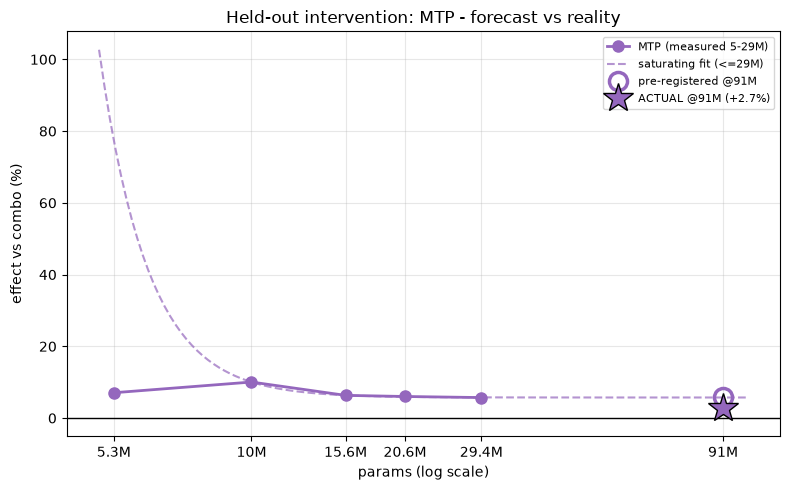

saved ../results/fig_mtp_heldout.png


In [9]:
# === GRADE the held-out MTP forecast at 91M + figure ===
import matplotlib.pyplot as plt
mtp = load_kv(RUNS_CSV, lambda r: (r[0], r[2]), lambda r: float(r[4]))
prereg = load_kv("../results/preregistered_mtp_91M.csv", lambda r: r[1], lambda r: float(r[2]))
ds = [100.0 * (mtp[("90M", s)] - v90[("combo", s)]) / v90[("combo", s)] for s in ("0", "1") if ("90M", s) in mtp]
act = float(np.mean(ds))
print(f"MTP @91M ACTUAL: {act:+.2f}%  (seeds: " + " ".join(f"{d:+.2f}" for d in ds) + ")")
for nm in ("linear", "saturating"):
    p = prereg[nm]
    print(f"  pre-registered {nm:10s} {p:+6.2f}%   err {p-act:+.2f}pp" +
          ("  sign OK" if (p < 0) == (act < 0) else "  SIGN WRONG"))
with open("../results/validation_mtp_graded.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["variant", "actual_pct", "pred_linear", "pred_saturating", "n_seeds"])
    w.writerow(["combo_mtp", f"{act:.3f}", prereg["linear"], prereg["saturating"], len(ds)])

pts_mtp = delta_points("combo_mtp", ORDER)
plt.figure(figsize=(8, 5)); plt.axhline(0, color="k", lw=1)
mm = [np.mean([y for z, x, y in pts_mtp if z == sz]) for sz in ORDER]
xs_o = [X[sz] for sz in ORDER]
plt.plot(xs_o, mm, "o-", color="tab:purple", ms=8, lw=2, label="MTP (measured 5-29M)")
sizes_fit, _ = monotone_suffix(ORDER, pts_mtp)
pts_fit = [p for p in pts_mtp if p[0] in sizes_fit]
sat = fit_sat(pts_fit)
xg = np.linspace(min(xs_o) - 0.03, X["90M"] + 0.05, 120)
plt.plot(xg, [sat_at(sat, x) for x in xg], "--", color="tab:purple", alpha=0.7, label="saturating fit (<=29M)")
plt.plot(X["90M"], prereg["saturating"], "o", mfc="none", mec="tab:purple", ms=13, mew=2.5, label="pre-registered @91M")
plt.plot(X["90M"], act, "*", color="tab:purple", ms=22, mec="k", label=f"ACTUAL @91M ({act:+.1f}%)")
plt.xticks(xs_o + [X["90M"]], ["5.3M", "10M", "15.6M", "20.6M", "29.4M", "91M"])
plt.xlabel("params (log scale)"); plt.ylabel("effect vs combo (%)")
plt.title("Held-out intervention: MTP - forecast vs reality")
plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("../results/fig_mtp_heldout.png", dpi=150)
plt.show(); print("saved ../results/fig_mtp_heldout.png")


## Reading this

This is the protocol applied blind, end-to-end, to an intervention it was not built on:
ladder -> monotone-suffix rule -> saturating + linear fits -> committed forecast -> verdict.
Whatever the grade, it goes in the paper as the held-out test. The retrodiction cell above also
documents how the saturating family would have done on conv/diff at 91M - the motivation for
adopting it before the 160M round (notebook 33).
